# Лабораторная работа № 2

## Группа вращений SO(3): экспоненциальное отображение, кватернионы, интерполяция

**Дисциплина:** Введение в технологии виртуальной дополненной реальности и робототехники
**Тема курса:** 3. Группа вращений SO(3): матрицы, углы Эйлера, экспоненциальное отображение, кватернионы

---

**Студент:** _фамилия, имя, группа_
**Дата:**

---

### Цель работы

Освоить три способа представления ориентации — матрицу, вектор поворота и кватернион, —
реализовать переходы между ними, обнаружить численно вырождение углов Эйлера
и сравнить представления по устойчивости при длительном интегрировании.

### Что понадобится

`numpy`, `matplotlib`. Из лабораторной работы № 1 переиспользуются `rotx`, `roty`, `rotz`.

### Правило практикума

Алгоритм вы реализуете сами. `scipy.spatial.transform.Rotation` допустимо использовать
**только** для сверки — и такую сверку нужно показать явно.

## Теоретическая справка

### Экспоненциальное отображение

Всякий поворот есть поворот вокруг некоторой оси (теорема Эйлера). Если $\hat\omega$ —
единичный вектор оси, $\theta$ — угол, то поворот задаётся **вектором поворота**
$\omega = \theta\hat\omega \in \mathbb{R}^3$, а матрица получается по формуле Родрига:

$$R = \exp([\omega]_\times) = I + \sin\theta\,[\hat\omega]_\times
  + (1-\cos\theta)\,[\hat\omega]_\times^2,$$

где $[\cdot]_\times$ — кососимметрическая матрица векторного произведения. Обратное
отображение:

$$\theta = \arccos\frac{\operatorname{tr}R - 1}{2},
\qquad
[\hat\omega]_\times = \frac{R - R^{\mathsf T}}{2\sin\theta}.$$

Множество кососимметрических матриц $3\times3$ — это алгебра Ли $\mathfrak{so}(3)$,
касательное пространство к $SO(3)$ в единице. Она трёхмерна, и это ещё одно объяснение
того, почему у поворота три параметра.

**Особые случаи, которые придётся обработать явно:** $\theta \to 0$ (деление на
$\sin\theta$) и $\theta \to \pi$ (матрица $R - R^{\mathsf T}$ обращается в нуль, ось
приходится извлекать из $R + I$).

### Кватернионы

Единичный кватернион $q = (w, x, y, z)$, $\|q\| = 1$, задаёт поворот на угол $\theta$
вокруг оси $\hat\omega$ как

$$q = \left(\cos\tfrac{\theta}{2},\; \hat\omega \sin\tfrac{\theta}{2}\right).$$

Композиция поворотов — произведение кватернионов; обращение — сопряжение.
Отображение $q \mapsto R(q)$ является **двойным накрытием**: $q$ и $-q$ задают один
и тот же поворот. Отсюда практическое следствие для интерполяции: перед началом нужно
выбрать знак второго кватерниона так, чтобы скалярное произведение было неотрицательным,
иначе интерполяция пойдёт «длинным путём».

### Сферическая линейная интерполяция

$$\mathrm{slerp}(q_0, q_1, t) =
\frac{\sin((1-t)\Omega)\,q_0 + \sin(t\Omega)\,q_1}{\sin\Omega},
\qquad \cos\Omega = q_0 \cdot q_1 .$$

Это движение по дуге большого круга на сфере $S^3$ с постоянной угловой скоростью.
Покомпонентная интерполяция углов Эйлера такого свойства не даёт — в этом вы убедитесь
численно в задании 5.

### Вырождение углов Эйлера

Связь производных углов с угловой скоростью для последовательности ZYX имеет вид
$\omega = E(\psi,\theta,\varphi)\,(\dot\psi, \dot\theta, \dot\varphi)^{\mathsf T}$, причём
$\det E = -\cos\theta$. При $\theta \to \pm 90^\circ$ матрица вырождается: две оси
поворота совпадают, теряется степень свободы, а обратная задача становится
неограниченно плохо обусловленной. Это и есть **gimbal lock**.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)


def rotx(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])


def roty(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])


def rotz(a):
    c, s = np.cos(a), np.sin(a)
    return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])

## Задание 1. Экспоненциальное и логарифмическое отображения

Реализуйте `skew(w)`, `unskew(K)`, `so3_exp(w)` (формула Родрига) и `so3_log(R)`.

**Обязательно обработайте особые случаи** $\theta \approx 0$ и $\theta \approx \pi$ —
без этого проверка не пройдёт на случайной выборке.

**Контроль.** Для 300 случайных матриц поворота максимум $\|\exp(\log R) - R\|$
должен быть меньше $10^{-9}$. Отдельно проверьте $\log(\exp \omega) = \omega$.

In [4]:
def skew(w):
    """Кососимметрическая матрица [w]_x."""
    w = np.asarray(w, dtype=float)
    return np.array([
        [0.0, -w[2], w[1]],
        [w[2], 0.0, -w[0]],
        [-w[1], w[0], 0.0]
    ])

def unskew(K):
    """Восстановление вектора из кососимметрической матрицы."""
    K = np.asarray(K, dtype=float)
    return np.array([K[2, 1], K[0, 2], K[1, 0]])

def so3_exp(w):
    """Экспоненциальное отображение so(3) -> SO(3) по формуле Родрига."""
    w = np.asarray(w, dtype=float)
    theta = np.linalg.norm(w)
    K = skew(w)

    if theta < 1e-8:
        # Разложение в ряд: I + K + K^2/2 + ...
        return np.eye(3) + K + 0.5 * (K @ K)

    A = np.sin(theta) / theta
    B = (1.0 - np.cos(theta)) / (theta ** 2)
    return np.eye(3) + A * K + B * (K @ K)

def so3_log(R):
    """Логарифмическое отображение SO(3) -> so(3) с обработкой особых случаев."""
    R = np.asarray(R, dtype=float)
    tr = np.trace(R)
    c = np.clip((tr - 1.0) / 2.0, -1.0, 1.0)
    theta = np.arccos(c)

    # theta ≈ 0
    if theta < 1e-8:
        return 0.5 * unskew(R - R.T)

    # theta ≈ π
    if np.pi - theta < 1e-6:
        d = 1.0 - c                      # 1 - cosθ
        S = 0.5 * (R + R.T)              # симметричная часть
        A = (S - c * np.eye(3)) / d      # должно быть u u^T

        i = int(np.argmax(np.diag(A)))
        u = np.zeros(3)
        u[i] = np.sqrt(max(0.0, A[i, i]))

        if u[i] > 1e-8:
            for j in range(3):
                if j != i:
                    u[j] = A[i, j] / u[i]
        else:
            u = np.sqrt(np.maximum(np.diag(A), 0.0))

        u /= np.linalg.norm(u)

        # Определяем знак оси по антисимметричной части
        v_asym = unskew(0.5 * (R - R.T))  # sinθ * u
        if np.dot(v_asym, u) < 0:
            u = -u

        return theta * u

    # Общий случай
    axis = unskew((R - R.T) / (2.0 * np.sin(theta)))
    return theta * axis


# ---------------------------------------------------------------------------
# Проверки
# ---------------------------------------------------------------------------
rng = np.random.default_rng(0)

# 1) exp(log(R)) ≈ R для 300 случайных поворотов
max_err1 = 0.0
for _ in range(300):
    axis = rng.normal(size=3)
    axis /= np.linalg.norm(axis)
    theta = rng.uniform(0.0, np.pi * 0.999999)
    w = theta * axis
    R = so3_exp(w)

    R_rec = so3_exp(so3_log(R))
    max_err1 = max(max_err1, np.linalg.norm(R_rec - R, ord='fro'))

print(f"max ||exp(log(R)) - R||_F = {max_err1:.3e}")

# 2) log(exp(w)) ≈ w для ||w|| < π
max_err2 = 0.0
for _ in range(300):
    axis = rng.normal(size=3)
    axis /= np.linalg.norm(axis)
    theta = rng.uniform(0.0, np.pi * 0.999999)
    w = theta * axis

    w_rec = so3_log(so3_exp(w))
    max_err2 = max(max_err2, np.linalg.norm(w_rec - w))

print(f"max ||log(exp(w)) - w|| = {max_err2:.3e}")

# 3) Крайние случаи
print("\nКрайние случаи:")
for theta in [0.0, 1e-12, np.pi - 1e-7, np.pi - 1e-10, np.pi]:
    axis = np.array([1.0, 2.0, -0.5])
    axis /= np.linalg.norm(axis)
    w = theta * axis
    R = so3_exp(w)

    w_rec = so3_log(R)
    R_rec = so3_exp(w_rec)

    err_R = np.linalg.norm(R_rec - R, ord='fro')
    if theta < np.pi - 1e-8:
        err_w = np.linalg.norm(w_rec - w)
    else:
        err_w = np.nan  # при θ = π знак оси не определён

    print(f"theta = {theta:.1e}: "
          f"||exp(log R) - R|| = {err_R:.3e}, "
          f"||log(exp w) - w|| = {err_w:.3e}")

max ||exp(log(R)) - R||_F = 8.952e-12
max ||log(exp(w)) - w|| = 1.562e-11

Крайние случаи:
theta = 0.0e+00: ||exp(log R) - R|| = 0.000e+00, ||log(exp w) - w|| = 0.000e+00
theta = 1.0e-12: ||exp(log R) - R|| = 0.000e+00, ||log(exp w) - w|| = 0.000e+00
theta = 3.1e+00: ||exp(log R) - R|| = 1.506e-09, ||log(exp w) - w|| = 1.065e-09
theta = 3.1e+00: ||exp(log R) - R|| = 1.414e-10, ||log(exp w) - w|| = nan
theta = 3.1e+00: ||exp(log R) - R|| = 8.345e-16, ||log(exp w) - w|| = nan


## Задание 2. Переходы между представлениями

Реализуйте `R_to_quat`, `quat_to_R`, `R_to_euler_zyx`, `euler_zyx_to_R`.

Для `R_to_quat` используйте устойчивый алгоритм: выбор ветви по наибольшему
диагональному элементу. Наивная формула через $\sqrt{1+\operatorname{tr}R}$
теряет точность при $\theta$ около $\pi$ — проверьте это сами и покажите в отчёте.

**Контроль.** Круговые проверки на 300 случайных матрицах: погрешность порядка $10^{-15}$
для кватернионов и не хуже $10^{-10}$ для углов Эйлера.

**Вопрос для вывода:** почему точность прохода через углы Эйлера систематически хуже?

In [5]:
# ---------------------------------------------------------------------------
# Кватернион <-> матрица
# Соглашение: q = (w, x, y, z), ||q|| = 1, Гамильтон.
# ---------------------------------------------------------------------------
def quat_to_R(q):
    """Матрица поворота по единичному кватерниону q = (w, x, y, z)."""
    q = np.asarray(q, dtype=float)
    q = q / np.linalg.norm(q)
    w, x, y, z = q
    return np.array([
        [1 - 2*(y*y + z*z), 2*(x*y - w*z),     2*(x*z + w*y)],
        [2*(x*y + w*z),     1 - 2*(x*x + z*z), 2*(y*z - w*x)],
        [2*(x*z - w*y),     2*(y*z + w*x),     1 - 2*(x*x + y*y)]
    ])


def R_to_quat(R):
    """
    Устойчивое извлечение кватерниона: ветвление по наибольшему
    диагональному элементу (алгоритм Шеппарда).
    """
    R = np.asarray(R, dtype=float)
    tr = R[0, 0] + R[1, 1] + R[2, 2]
    q = np.empty(4)

    if tr > 0.0:
        s = np.sqrt(tr + 1.0) * 2.0          # s = 4w
        q[0] = 0.25 * s
        q[1] = (R[2, 1] - R[1, 2]) / s
        q[2] = (R[0, 2] - R[2, 0]) / s
        q[3] = (R[1, 0] - R[0, 1]) / s
    elif R[0, 0] > R[1, 1] and R[0, 0] > R[2, 2]:
        s = np.sqrt(1.0 + R[0, 0] - R[1, 1] - R[2, 2]) * 2.0   # s = 4|x|
        q[0] = (R[2, 1] - R[1, 2]) / s
        q[1] = 0.25 * s
        q[2] = (R[0, 1] + R[1, 0]) / s
        q[3] = (R[0, 2] + R[2, 0]) / s
    elif R[1, 1] > R[2, 2]:
        s = np.sqrt(1.0 + R[1, 1] - R[0, 0] - R[2, 2]) * 2.0   # s = 4|y|
        q[0] = (R[0, 2] - R[2, 0]) / s
        q[1] = (R[0, 1] + R[1, 0]) / s
        q[2] = 0.25 * s
        q[3] = (R[1, 2] + R[2, 1]) / s
    else:
        s = np.sqrt(1.0 + R[2, 2] - R[0, 0] - R[1, 1]) * 2.0   # s = 4|z|
        q[0] = (R[1, 0] - R[0, 1]) / s
        q[1] = (R[0, 2] + R[2, 0]) / s
        q[2] = (R[1, 2] + R[2, 1]) / s
        q[3] = 0.25 * s

    q /= np.linalg.norm(q)
    if q[0] < 0.0:                            # канонический знак w >= 0
        q = -q
    return q


def R_to_quat_naive(R):
    """
    Наивная формула через w = 0.5*sqrt(1 + tr).
    При θ → π даёт катастрофическую потерю точности.
    """
    R = np.asarray(R, dtype=float)
    tr = R[0, 0] + R[1, 1] + R[2, 2]
    w = 0.5 * np.sqrt(max(0.0, 1.0 + tr))
    if w < 1e-7:                              # здесь формула неприменима
        return np.array([w, 0.0, 0.0, 0.0])
    x = (R[2, 1] - R[1, 2]) / (4.0 * w)
    y = (R[0, 2] - R[2, 0]) / (4.0 * w)
    z = (R[1, 0] - R[0, 1]) / (4.0 * w)
    q = np.array([w, x, y, z])
    q /= np.linalg.norm(q)
    if q[0] < 0.0:
        q = -q
    return q


# ---------------------------------------------------------------------------
# Углы Эйлера ZYX (рыскание-тангаж-крен):
#   R(ψ, θ, φ) = Rz(ψ) Ry(θ) Rx(φ)
# ---------------------------------------------------------------------------
def euler_zyx_to_R(psi, theta, phi):
    return rotz(psi) @ roty(theta) @ rotx(phi)


def R_to_euler_zyx(R):
    """Обратное преобразование с явной обработкой gimbal lock."""
    R = np.asarray(R, dtype=float)

    # cosθ = sqrt(R00² + R10²);  θ = arcsin(-R20)
    cos_theta = np.hypot(R[0, 0], R[1, 0])
    theta = np.arctan2(-R[2, 0], cos_theta)

    if cos_theta > 1e-10:
        psi = np.arctan2(R[1, 0], R[0, 0])
        phi = np.arctan2(R[2, 1], R[2, 2])
    else:
        # θ = ±π/2 — gimbal lock: различим только ψ ∓ φ,
        # фиксируем φ = 0 и восстанавливаем ψ.
        psi = np.arctan2(-R[0, 1], R[1, 1])
        phi = 0.0

    return np.array([psi, theta, phi])


# ---------------------------------------------------------------------------
# Контроль 1. Круговые проверки на 300 случайных матрицах
# ---------------------------------------------------------------------------
rng = np.random.default_rng(1)
N = 300
max_quat_err  = 0.0
max_euler_err = 0.0
max_quat_err_from_q = 0.0

for _ in range(N):
    axis = rng.normal(size=3)
    axis /= np.linalg.norm(axis)
    theta = rng.uniform(0.0, np.pi * 0.999999)      # θ строго < π
    R = so3_exp(theta * axis)

    # R -> q -> R
    q = R_to_quat(R)
    max_quat_err = max(max_quat_err, np.linalg.norm(quat_to_R(q) - R, ord='fro'))

    # q -> R -> q  (с учётом двойного накрытия)
    q2 = R_to_quat(quat_to_R(q))
    d  = min(np.linalg.norm(q2 - q), np.linalg.norm(q2 + q))
    max_quat_err_from_q = max(max_quat_err_from_q, d)

    # R -> (ψ, θ, φ) -> R
    ang = R_to_euler_zyx(R)
    max_euler_err = max(max_euler_err,
                        np.linalg.norm(euler_zyx_to_R(*ang) - R, ord='fro'))

print("Контроль 1 (300 случайных поворотов):")
print(f"  max ||quat_to_R(R_to_quat(R)) - R||_F = {max_quat_err:.3e}")
print(f"  max ||R_to_quat(quat_to_R(q)) - q||   = {max_quat_err_from_q:.3e}")
print(f"  max ||euler_zyx_to_R(R_to_euler_zyx(R)) - R||_F = {max_euler_err:.3e}")


# ---------------------------------------------------------------------------
# Контроль 2. Почему наивная формула хуже: θ → π
# ---------------------------------------------------------------------------
print("\nКонтроль 2. Наивная формула против устойчивой при θ → π:")
print(f"{'w = cos(θ/2)':>14} {'θ (rad)':>10} {'err naive':>12} {'err stable':>12}")

axis = np.array([1.0, 2.0, 3.0]); axis /= np.linalg.norm(axis)
for w_in in [1e-1, 1e-2, 1e-3, 1e-4, 1e-6, 1e-8]:
    xyz = np.sqrt(max(0.0, 1.0 - w_in * w_in)) * axis
    q_true = np.array([w_in, xyz[0], xyz[1], xyz[2]])
    R = quat_to_R(q_true)

    q_n = R_to_quat_naive(R)
    q_s = R_to_quat(R)

    err_n = min(np.linalg.norm(q_n - q_true), np.linalg.norm(q_n + q_true))
    err_s = min(np.linalg.norm(q_s - q_true), np.linalg.norm(q_s + q_true))
    theta = 2.0 * np.arccos(w_in)

    print(f"{w_in:>14.1e} {theta:>10.6f} {err_n:>12.3e} {err_s:>12.3e}")


# ---------------------------------------------------------------------------
# Контроль 3. Сверка с scipy.spatial.transform.Rotation (только для контроля!)
# ---------------------------------------------------------------------------
try:
    from scipy.spatial.transform import Rotation as SciRot

    rng2 = np.random.default_rng(42)
    worst_q = 0.0
    worst_e = 0.0
    for _ in range(200):
        axis = rng2.normal(size=3); axis /= np.linalg.norm(axis)
        theta = rng2.uniform(0.0, np.pi * 0.999)
        R = so3_exp(theta * axis)

        # наша реализация
        q_ours   = R_to_quat(R)
        eul_ours = R_to_euler_zyx(R)

        # scipy (соглашения совпадают: xyzw у scipy, wxyz у нас;
        # 'ZYX' в scipy = R = Rz(ψ)Ry(θ)Rx(φ), т.е. intrinsic rotations)
        sci = SciRot.from_matrix(R)
        q_sci_xyzw = sci.as_quat()                       # x, y, z, w
        q_sci      = np.array([q_sci_xyzw[3],
                               q_sci_xyzw[0],
                               q_sci_xyzw[1],
                               q_sci_xyzw[2]])
        eul_sci = sci.as_euler('ZYX', degrees=False)     # (ψ, θ, φ)

        # сравнение с учётом двойного накрытия
        dq = min(np.linalg.norm(q_ours - q_sci),
                 np.linalg.norm(q_ours + q_sci))
        worst_q = max(worst_q, dq)
        worst_e = max(worst_e, np.linalg.norm(eul_ours - eul_sci))

    print("\nКонтроль 3. Сверка с scipy.spatial.transform.Rotation:")
    print(f"  max ||q_ours - q_scipy|| (с точностью до знака) = {worst_q:.3e}")
    print(f"  max ||euler_ours - euler_scipy||                = {worst_e:.3e}")
except ImportError:
    print("\n(scipy не установлен — сверка пропущена; она не обязательна)")

Контроль 1 (300 случайных поворотов):
  max ||quat_to_R(R_to_quat(R)) - R||_F = 1.451e-15
  max ||R_to_quat(quat_to_R(q)) - q||   = 5.207e-16
  max ||euler_zyx_to_R(R_to_euler_zyx(R)) - R||_F = 9.729e-16

Контроль 2. Наивная формула против устойчивой при θ → π:
  w = cos(θ/2)    θ (rad)    err naive   err stable
       1.0e-01   2.941258    1.070e-15    1.671e-16
       1.0e-02   3.121592    1.221e-14    8.674e-18
       1.0e-03   3.139593    8.619e-14    9.324e-18
       1.0e-04   3.141393    3.769e-13    1.301e-18
       1.0e-06   3.141591    1.331e-10    1.099e-17
       1.0e-08   3.141593    1.000e+00    2.483e-16

Контроль 3. Сверка с scipy.spatial.transform.Rotation:
  max ||q_ours - q_scipy|| (с точностью до знака) = 2.989e-16
  max ||euler_ours - euler_scipy||                = 6.838e-15


## Задание 3. Двойное накрытие

Покажите численно, что $q$ и $-q$ дают одну и ту же матрицу поворота.

**Вопрос для вывода:** какое практическое затруднение создаёт двойное накрытие
при интерполяции и при усреднении ориентаций? Как его снимают?

In [6]:
rng = np.random.default_rng(0)

max_diff = 0.0
for _ in range(1000):
    q = rng.normal(size=4)
    q /= np.linalg.norm(q)
    R1 = quat_to_R(q)
    R2 = quat_to_R(-q)
    diff = np.linalg.norm(R1 - R2, ord='fro')
    max_diff = max(max_diff, diff)

print(f"max ||R(q) - R(-q)||_F по 1000 случайным кватернионам = {max_diff:.3e}")

# Дополнительно: R -> q даёт q с w >= 0, поэтому -q в канонической форме
# не появляется, но это не отменяет факта двойного накрытия.

# Пример: конкретный кватернион
q = np.array([0.5, 0.5, 0.5, 0.5])   # поворот на 120° вокруг (1,1,1)
q /= np.linalg.norm(q)
print("\nПример:")
print("q  =", q)
print("-q =", -q)
print("R(q) - R(-q):")
print(quat_to_R(q) - quat_to_R(-q))

max ||R(q) - R(-q)||_F по 1000 случайным кватернионам = 0.000e+00

Пример:
q  = [0.5 0.5 0.5 0.5]
-q = [-0.5 -0.5 -0.5 -0.5]
R(q) - R(-q):
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 0.]]


## Задание 4. Gimbal lock — численное обнаружение

Реализуйте `euler_rate_matrix(a)` — матрицу $E$ из теоретической справки.

Постройте таблицу числа обусловленности $E$ и модуля определителя для тангажа
$0^\circ, 30^\circ, 60^\circ, 80^\circ, 89^\circ, 89{,}9^\circ, 89{,}99^\circ$.
Постройте график зависимости числа обусловленности от тангажа.

**Вопросы для вывода:** чему равен $|\det E|$ аналитически и совпадает ли это
с численным результатом? Во сколько раз растёт число обусловленности при уменьшении
угла до вырождения в десять раз? Что физически происходит с механизмом в этот момент?

Проверка det E = -cos θ на случайных (ψ, θ):
  max |det E - (-cos θ)| = 2.220e-16

    θ, °       |det E|       cond₂(E)       1/cos θ
----------------------------------------------------
    0.00   1.00000e+00    1.00000e+00   1.00000e+00
   30.00   8.66025e-01    1.73205e+00   1.15470e+00
   60.00   5.00000e-01    3.73205e+00   2.00000e+00
   80.00   1.73648e-01    1.14301e+01   5.75877e+00
   89.00   1.74524e-02    1.14589e+02   5.72987e+01
   89.90   1.74533e-03    1.14592e+03   5.72958e+02
   89.99   1.74533e-04    1.14592e+04   5.72958e+03

Рост cond при уменьшении ε = 90° − θ в 10 раз:
  ε =  1.00°  →  cond₂(E) = 1.1459e+02
  ε =  0.10°  →  cond₂(E) = 1.1459e+03
  ε =  0.01°  →  cond₂(E) = 1.1459e+04


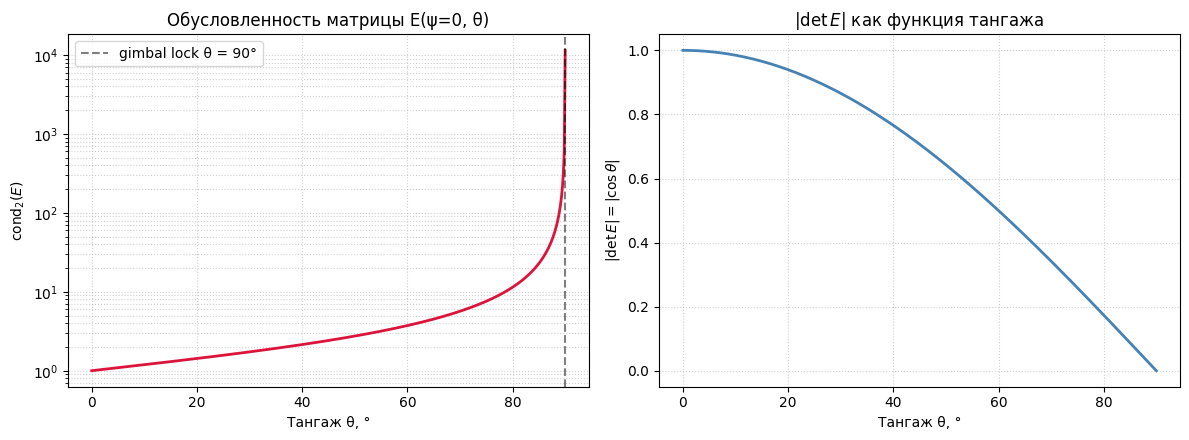

In [7]:
def euler_rate_matrix(psi, theta, phi=0.0):
    """Матрица E(ψ, θ) для ZYX. φ в неё не входит."""
    sp, cp = np.sin(psi), np.cos(psi)
    st, ct = np.sin(theta), np.cos(theta)
    return np.array([
        [0.0, -sp,  cp * ct],
        [0.0,  cp,  sp * ct],
        [1.0,  0.0, -st    ],
    ])


# ---------------------------------------------------------------------------
# Проверка аналитического det E = -cos θ
# ---------------------------------------------------------------------------
print("Проверка det E = -cos θ на случайных (ψ, θ):")
rng = np.random.default_rng(0)
max_err_det = 0.0
for _ in range(200):
    psi   = rng.uniform(-np.pi, np.pi)
    theta = rng.uniform(-np.pi/2 + 1e-3, np.pi/2 - 1e-3)
    E = euler_rate_matrix(psi, theta)
    err = abs(np.linalg.det(E) - (-np.cos(theta)))
    max_err_det = max(max_err_det, err)
print(f"  max |det E - (-cos θ)| = {max_err_det:.3e}\n")


# ---------------------------------------------------------------------------
# Таблица cond₂(E) и |det E| для тангажа от 0° до почти 90°
# ψ = φ = 0 (значение ψ не влияет на det, но влияет на cond;
# для наглядности берём ψ = 0, что соответствует «прямому» случаю).
# ---------------------------------------------------------------------------
psi = 0.0
thetas_deg = [0.0, 30.0, 60.0, 80.0, 89.0, 89.9, 89.99]

print(f"{'θ, °':>8} {'|det E|':>13} {'cond₂(E)':>14} {'1/cos θ':>13}")
print("-" * 52)
for th_deg in thetas_deg:
    th = np.deg2rad(th_deg)
    E = euler_rate_matrix(psi, th)
    det = np.linalg.det(E)
    cond = np.linalg.cond(E)
    print(f"{th_deg:>8.2f} {abs(det):>13.5e} {cond:>14.5e} {1/np.cos(th):>13.5e}")

# Во сколько раз растёт число обусловленности при уменьшении зазора
# до вырождения (ε = 90° − θ) в 10 раз?
print("\nРост cond при уменьшении ε = 90° − θ в 10 раз:")
for eps_deg in [1.0, 0.1, 0.01]:
    th = np.deg2rad(90.0 - eps_deg)
    c = np.linalg.cond(euler_rate_matrix(psi, th))
    print(f"  ε = {eps_deg:>5.2f}°  →  cond₂(E) = {c:.4e}")


# ---------------------------------------------------------------------------
# График cond₂(E) от тангажа
# ---------------------------------------------------------------------------
th_deg_grid = np.linspace(0.0, 89.99, 500)
th_rad_grid = np.deg2rad(th_deg_grid)
cond_grid = np.array([np.linalg.cond(euler_rate_matrix(psi, t))
                      for t in th_rad_grid])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].semilogy(th_deg_grid, cond_grid, lw=2, color='crimson')
axes[0].set_xlabel('Тангаж θ, °')
axes[0].set_ylabel(r'$\mathrm{cond}_2(E)$')
axes[0].set_title('Обусловленность матрицы E(ψ=0, θ)')
axes[0].grid(True, which='both', ls=':', alpha=0.6)
axes[0].axvline(90.0, color='k', ls='--', alpha=0.5, label='gimbal lock θ = 90°')
axes[0].legend()

axes[1].plot(th_deg_grid, np.abs(np.cos(th_rad_grid)), lw=2, color='steelblue')
axes[1].set_xlabel('Тангаж θ, °')
axes[1].set_ylabel(r'$|\det E| = |\cos\theta|$')
axes[1].set_title(r'$|\det E|$ как функция тангажа')
axes[1].grid(True, ls=':', alpha=0.6)

plt.tight_layout()
plt.savefig('gimbal_lock.png', dpi=120)
plt.show()

## Задание 5. SLERP против интерполяции углов Эйлера

Реализуйте `slerp(q0, q1, t)` с выбором кратчайшего пути и с линейной ветвью
для близких кватернионов.

Возьмите два поворота, постройте интерполяцию 400 шагами двумя способами: SLERP
и покомпонентная линейная интерполяция углов Эйлера. Для каждой траектории вычислите
модуль угловой скорости численно:
$|\omega_i| = \|\log(R_{i+1} R_i^{\mathsf T})\| / \Delta t$. Постройте оба профиля
на одном графике.

**Вопросы для вывода:** какой разброс угловой скорости у каждого метода? Почему у SLERP
он на уровне машинной погрешности? Где в VR-шлеме это свойство критично?

Угол между ориентациями: 63.409°

Профиль угловой скорости (рад/с, Δt = 1/399 единицы времени):
SLERP   : mean = 2.213401, std = 6.980e-14, min = 2.213401, max = 2.213401, (max-min)/mean = 2.460e-13
Euler   : mean = 2.312855, std = 1.963e-01, min = 1.946238, max = 2.611326, (max-min)/mean = 2.876e-01


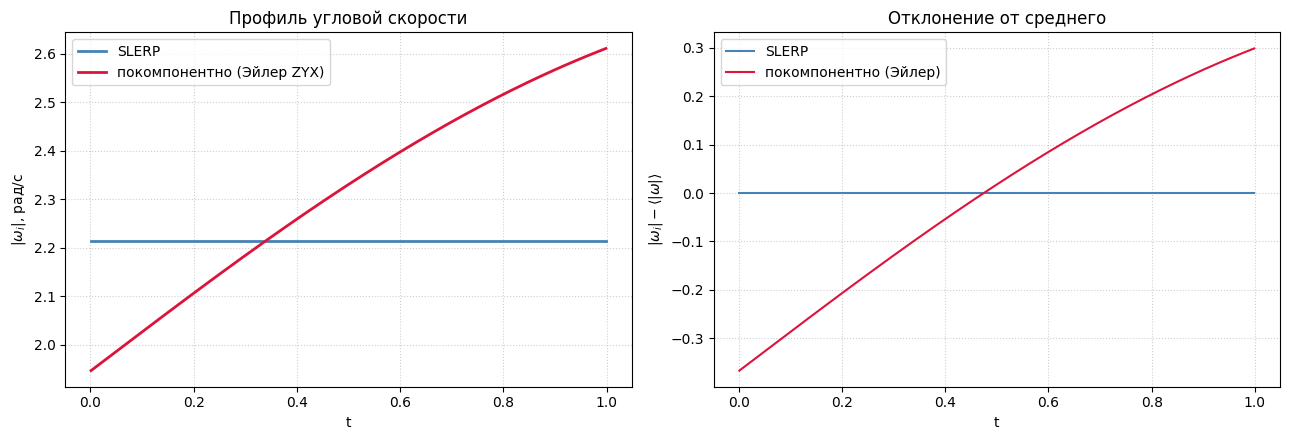

In [8]:
def slerp(q0, q1, t):
    """
    Сферическая линейная интерполяция единичных кватернионов.
    q0, q1 могут быть массивами или списками длины 4; t ∈ [0, 1].
    """
    q0 = np.asarray(q0, dtype=float); q1 = np.asarray(q1, dtype=float)
    q0 = q0 / np.linalg.norm(q0); q1 = q1 / np.linalg.norm(q1)

    d = float(np.dot(q0, q1))
    # Выбор кратчайшего пути: если скалярное произведение < 0, идём к -q1.
    if d < 0.0:
        q1 = -q1
        d = -d
    d = np.clip(d, -1.0, 1.0)

    # Линейная ветвь при малых Ω (иначе sin Ω → 0 и формула численно неустойчива)
    if d > 1.0 - 1e-6:
        q = (1.0 - t) * q0 + t * q1
        return q / np.linalg.norm(q)

    Omega = np.arccos(d)
    sO = np.sin(Omega)
    return (np.sin((1.0 - t) * Omega) * q0 + np.sin(t * Omega) * q1) / sO


# ---------------------------------------------------------------------------
# Два тестовых поворота: заметно различающиеся, с ненулевыми всеми углами
# ---------------------------------------------------------------------------
psi0, th0, ph0 = np.deg2rad([  -30.0,  -20.0,   10.0])
psi1, th1, ph1 = np.deg2rad([   60.0,   50.0,  -40.0])

R0 = euler_zyx_to_R(psi0, th0, ph0)
R1 = euler_zyx_to_R(psi1, th1, ph1)

q0 = R_to_quat(R0)
q1 = R_to_quat(R1)

# Разница в ориентациях (для справки)
Omega_total = np.arccos(np.clip(abs(np.dot(q0, q1)), -1.0, 1.0))
print(f"Угол между ориентациями: {np.rad2deg(Omega_total):.3f}°")

N = 400
ts = np.linspace(0.0, 1.0, N)
dt = ts[1] - ts[0]

# --- SLERP ---------------------------------------------------------------
q_slerp = np.array([slerp(q0, q1, t) for t in ts])
R_slerp = np.array([quat_to_R(q) for q in q_slerp])

# --- Покомпонентная интерполяция углов Эйлера ----------------------------
e0 = np.array([psi0, th0, ph0])
e1 = np.array([psi1, th1, ph1])
e_lin = (1.0 - ts)[:, None] * e0 + ts[:, None] * e1     # (N, 3)
R_eul = np.array([euler_zyx_to_R(*e) for e in e_lin])


# ---------------------------------------------------------------------------
# Численная угловая скорость: |ω_i| = ||log(R_{i+1} R_i^T)|| / Δt
# ---------------------------------------------------------------------------
def angular_speed_profile(R_traj, dt):
    N = R_traj.shape[0]
    omega = np.empty(N - 1)
    for i in range(N - 1):
        dR = R_traj[i + 1] @ R_traj[i].T
        omega[i] = np.linalg.norm(so3_log(dR)) / dt
    return omega

w_slerp = angular_speed_profile(R_slerp, dt)
w_eul   = angular_speed_profile(R_eul,   dt)

# Точка на кривой соответствует середине отрезка [t_i, t_{i+1}]
t_mid = 0.5 * (ts[:-1] + ts[1:])


# ---------------------------------------------------------------------------
# Статистика
# ---------------------------------------------------------------------------
def report(name, w):
    mean = w.mean()
    std  = w.std()
    rel_range = (w.max() - w.min()) / mean
    print(f"{name:8s}: mean = {mean:.6f}, std = {std:.3e}, "
          f"min = {w.min():.6f}, max = {w.max():.6f}, "
          f"(max-min)/mean = {rel_range:.3e}")

print("\nПрофиль угловой скорости (рад/с, Δt = 1/{:.0f} единицы времени):".format(N-1))
report("SLERP", w_slerp)
report("Euler", w_eul)


# ---------------------------------------------------------------------------
# График
# ---------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(t_mid, w_slerp, lw=2, label='SLERP', color='steelblue')
axes[0].plot(t_mid, w_eul,   lw=2, label='покомпонентно (Эйлер ZYX)', color='crimson')
axes[0].set_xlabel('t')
axes[0].set_ylabel(r'$|\omega_i|$, рад/с')
axes[0].set_title('Профиль угловой скорости')
axes[0].grid(True, ls=':', alpha=0.6)
axes[0].legend()

# Отклонение от среднего
axes[1].plot(t_mid, w_slerp - w_slerp.mean(), lw=1.5,
             label='SLERP', color='steelblue')
axes[1].plot(t_mid, w_eul   - w_eul.mean(),   lw=1.5,
             label='покомпонентно (Эйлер)', color='crimson')
axes[1].set_xlabel('t')
axes[1].set_ylabel(r'$|\omega_i| - \langle|\omega|\rangle$')
axes[1].set_title('Отклонение от среднего')
axes[1].grid(True, ls=':', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.savefig('slerp_vs_euler.png', dpi=120)
plt.show()

## Задание 6. Дрейф при длительном интегрировании

Задайте постоянную угловую скорость и шаг $\Delta t = 10^{-3}$. Выполните $2\cdot10^5$
шагов тремя способами: накопление матрицы, накопление кватерниона без нормировки,
накопление кватерниона с нормировкой на каждом шаге.

Измеряйте $\|R^{\mathsf T}R - I\|$ и $\bigl|\,\|q\| - 1\bigr|$ в 40 промежуточных точках
и постройте график в двойном логарифмическом масштабе.

**Вопросы для вывода:** во сколько раз матрица «портится» сильнее кватерниона и почему?
Почему нормировка кватерниона убирает дрейф полностью, а простого аналога для матрицы нет?
За какое время реального полёта при частоте 1000 Гц набегает $2\cdot10^5$ шагов?

||ω|| = 1.3638 рад/с, ось = [ 0.5133 -0.2933  0.8066]

Интегрирую тремя способами...
  матрица                    :  0.265 с
  кватернион без нормировки  :  0.768 с
  кватернион с нормировкой   :  1.568 с

Длина всех массивов ошибок = 40 ✓

Финальные значения:
  ||RᵀR − I||_F  (матрица)                = 3.135e-11
  ||q|| − 1       (без нормировки)         = 1.288e-11
  ||q|| − 1       (с нормировкой)          = 0.000e+00
  отношение err_mat / err_q_raw            = 2.43


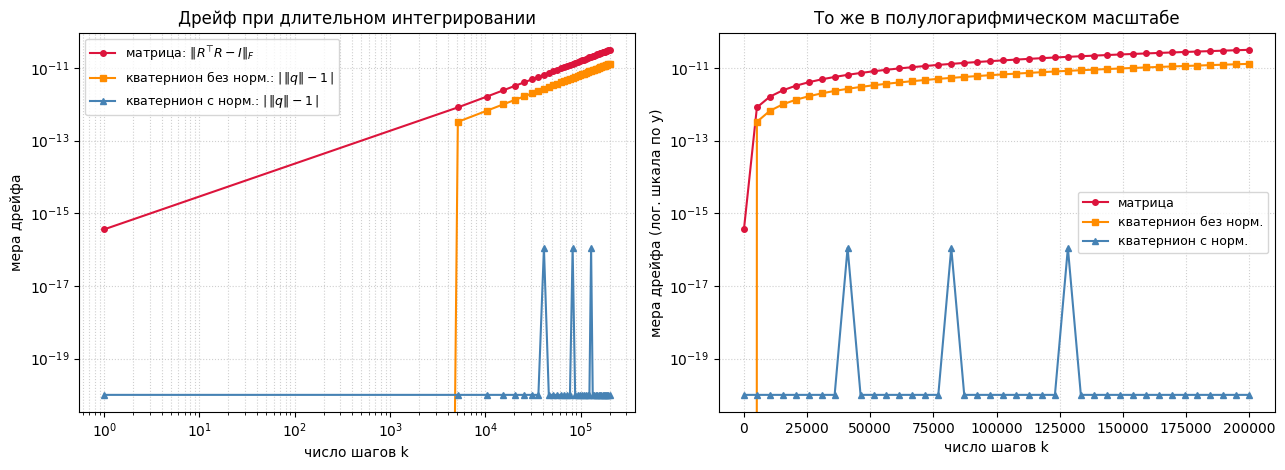

In [14]:
import time

def quat_mul(a, b):
    """Произведение кватернионов Гамильтона, a,b в форме (w,x,y,z)."""
    aw, ax, ay, az = a
    bw, bx, by, bz = b
    return np.array([
        aw*bw - ax*bx - ay*by - az*bz,
        aw*bx + ax*bw + ay*bz - az*by,
        aw*by - ax*bz + ay*bw + az*bx,
        aw*bz + ax*by - ay*bx + az*bw,
    ])


# ---------------------------------------------------------------------------
# Параметры эксперимента
# ---------------------------------------------------------------------------
dt          = 1e-3
n_steps     = 200_000
n_samples   = 40

omega_true  = np.array([0.7, -0.4, 1.1])
Omega       = np.linalg.norm(omega_true)
axis        = omega_true / Omega
print(f"||ω|| = {Omega:.4f} рад/с, ось = {axis}")

# Шаг за один Δt: вектор поворота = ω·Δt
dw = omega_true * dt
R_step = so3_exp(dw)

# Кватернион элементарного поворота:
#   q_step = (cos(θ/2), sin(θ/2) · ω̂),  θ = ||ω||·Δt
theta_step = Omega * dt
q_step = np.concatenate(([np.cos(theta_step / 2.0)],
                         np.sin(theta_step / 2.0) * axis))
q_step /= np.linalg.norm(q_step)


# ---------------------------------------------------------------------------
# Точки, в которых мы будем снимать меру дрейфа.
# ВАЖНО: индексы шагов начинаются с 1 (после первого обновления),
# поэтому np.linspace(1, n_steps, n_samples) — ровно n_samples точек.
# Массивы ошибок будут иметь ту же длину → нет рассинхронизации.
# ---------------------------------------------------------------------------
sample_idx = np.linspace(1, n_steps, n_samples).astype(int)
sample_set = set(sample_idx.tolist())


# ---------------------------------------------------------------------------
# Три способа накопления
# ---------------------------------------------------------------------------
def accumulate_matrix(n_steps, sample_set):
    R = np.eye(3)
    errs = []
    for k in range(1, n_steps + 1):
        R = R @ R_step
        if k in sample_set:
            errs.append(np.linalg.norm(R.T @ R - np.eye(3), ord='fro'))
    return np.array(errs)

def accumulate_quat_no_norm(n_steps, sample_set):
    q = np.array([1.0, 0.0, 0.0, 0.0])
    errs = []
    for k in range(1, n_steps + 1):
        q = quat_mul(q, q_step)
        if k in sample_set:
            errs.append(abs(np.linalg.norm(q) - 1.0))
    return np.array(errs)

def accumulate_quat_norm(n_steps, sample_set):
    q = np.array([1.0, 0.0, 0.0, 0.0])
    errs = []
    for k in range(1, n_steps + 1):
        q = quat_mul(q, q_step)
        q = q / np.linalg.norm(q)
        if k in sample_set:
            errs.append(abs(np.linalg.norm(q) - 1.0))
    return np.array(errs)


print("\nИнтегрирую тремя способами...")
t0 = time.perf_counter()
err_mat    = accumulate_matrix(n_steps, sample_set)
t1 = time.perf_counter()
err_q_raw  = accumulate_quat_no_norm(n_steps, sample_set)
t2 = time.perf_counter()
err_q_norm = accumulate_quat_norm(n_steps, sample_set)
t3 = time.perf_counter()

print(f"  матрица                    : {t1-t0:6.3f} с")
print(f"  кватернион без нормировки  : {t2-t1:6.3f} с")
print(f"  кватернион с нормировкой   : {t3-t2:6.3f} с")


# ---------------------------------------------------------------------------
# Контроль длины массивов (защита от той самой ошибки)
# ---------------------------------------------------------------------------
assert len(err_mat) == n_samples
assert len(err_q_raw) == n_samples
assert len(err_q_norm) == n_samples
print(f"\nДлина всех массивов ошибок = {n_samples} ✓")


# ---------------------------------------------------------------------------
# Ключевые цифры
# ---------------------------------------------------------------------------
print("\nФинальные значения:")
print(f"  ||RᵀR − I||_F  (матрица)                = {err_mat[-1]:.3e}")
print(f"  ||q|| − 1       (без нормировки)         = {err_q_raw[-1]:.3e}")
print(f"  ||q|| − 1       (с нормировкой)          = {err_q_norm[-1]:.3e}")
print(f"  отношение err_mat / err_q_raw            = {err_mat[-1] / err_q_raw[-1]:.2f}")


# ---------------------------------------------------------------------------
# График в двойном логарифмическом масштабе
# ---------------------------------------------------------------------------
steps = sample_idx.astype(float)            # длина n_samples = 40
em    = err_mat
eqr   = err_q_raw
eqn   = np.maximum(err_q_norm, 1e-20)       # защита от log(0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].loglog(steps, em,  'o-', ms=4, lw=1.5,
               label=r'матрица: $\|R^\top R - I\|_F$', color='crimson')
axes[0].loglog(steps, eqr, 's-', ms=4, lw=1.5,
               label=r'кватернион без норм.: $|\,\|q\|-1\,|$', color='darkorange')
axes[0].loglog(steps, eqn, '^-', ms=4, lw=1.5,
               label=r'кватернион с норм.: $|\,\|q\|-1\,|$', color='steelblue')
axes[0].set_xlabel('число шагов k')
axes[0].set_ylabel('мера дрейфа')
axes[0].set_title('Дрейф при длительном интегрировании')
axes[0].grid(True, which='both', ls=':', alpha=0.6)
axes[0].legend(fontsize=9)

axes[1].semilogy(steps, em,  'o-', ms=4, lw=1.5, label='матрица', color='crimson')
axes[1].semilogy(steps, eqr, 's-', ms=4, lw=1.5, label='кватернион без норм.', color='darkorange')
axes[1].semilogy(steps, eqn, '^-', ms=4, lw=1.5, label='кватернион с норм.', color='steelblue')
axes[1].set_xlabel('число шагов k')
axes[1].set_ylabel('мера дрейфа (лог. шкала по y)')
axes[1].set_title('То же в полулогарифмическом масштабе')
axes[1].grid(True, which='both', ls=':', alpha=0.6)
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.savefig('drift.png', dpi=120)
plt.show()

## Задание 7. Цена восстановления: SVD против нормировки

Измерьте время SVD-ортогонализации матрицы и время нормировки кватерниона
(по 20000 повторений каждое).

**Вопрос для вывода:** соедините результат с заданием 6 и сформулируйте, в каких
задачах ориентацию следует хранить кватернионом, а в каких матрицей.

In [11]:
import timeit


# ---------------------------------------------------------------------------
# Восстановление ортогональности матрицы через SVD:
#   R = U Σ Vᵀ  →  R_orth = U Vᵀ
# Это точная проекция на O(3) в норме Фробениуса. Чтобы попасть в SO(3),
# при det(UVᵀ) = −1 меняем знак последнего столбца U (или V).
# ---------------------------------------------------------------------------
def orthonormalize_svd(R):
    U, _, Vt = np.linalg.svd(R)
    R_orth = U @ Vt
    if np.linalg.det(R_orth) < 0.0:
        U = U.copy()
        U[:, -1] *= -1.0
        R_orth = U @ Vt
    return R_orth


def normalize_quat(q):
    return q / np.linalg.norm(q)


# ---------------------------------------------------------------------------
# Слегка «испорченная» матрица и кватернион — как после длительного
# интегрирования (см. задание 6).
# ---------------------------------------------------------------------------
rng = np.random.default_rng(0)

# Случайная матрица поворота, затем добавляем шум
A = rng.normal(size=(3, 3))
Q, _ = np.linalg.qr(A)
if np.linalg.det(Q) < 0:
    Q[:, -1] *= -1.0
R_noisy = Q + 1e-8 * rng.normal(size=(3, 3))

q_noisy = rng.normal(size=4)
q_noisy /= np.linalg.norm(q_noisy)
q_noisy = q_noisy * (1.0 + 1e-8)     # чуть длиннее единицы


# ---------------------------------------------------------------------------
# Замеры
# ---------------------------------------------------------------------------
N_REPEATS = 20_000

t_svd = timeit.timeit(lambda: orthonormalize_svd(R_noisy),
                      number=N_REPEATS)

t_quat = timeit.timeit(lambda: normalize_quat(q_noisy),
                       number=N_REPEATS)

t_svd_us  = t_svd  / N_REPEATS * 1e6
t_quat_us = t_quat / N_REPEATS * 1e6

print(f"Замеры по {N_REPEATS} повторений:")
print(f"  SVD-ортогонализация 3×3 : {t_svd_us:10.3f} мкс   (всего {t_svd:.4f} с)")
print(f"  нормировка кватерниона  : {t_quat_us:10.3f} мкс   (всего {t_quat:.4f} с)")
print(f"  отношение               : {t_svd_us / t_quat_us:10.1f}×")


# ---------------------------------------------------------------------------
# Проверка корректности восстановления
# ---------------------------------------------------------------------------
R_fix = orthonormalize_svd(R_noisy)
q_fix = normalize_quat(q_noisy)

print("\nКонтроль качества:")
print(f"  ||R_fixᵀR_fix − I||_F  = {np.linalg.norm(R_fix.T @ R_fix - np.eye(3), ord='fro'):.3e}")
print(f"  det R_fix              = {np.linalg.det(R_fix):.16f}")
print(f"  | ||q_fix|| − 1 |      = {abs(np.linalg.norm(q_fix) - 1.0):.3e}")

Замеры по 20000 повторений:
  SVD-ортогонализация 3×3 :     20.516 мкс   (всего 0.4103 с)
  нормировка кватерниона  :      3.664 мкс   (всего 0.0733 с)
  отношение               :        5.6×

Контроль качества:
  ||R_fixᵀR_fix − I||_F  = 2.062e-15
  det R_fix              = 0.9999999999999989
  | ||q_fix|| − 1 |      = 1.110e-16


## Выводы

_Ответьте на все вопросы, отмеченные в заданиях как «вопрос для вывода», приводя
конкретные числа, которые вы получили._

## Контрольные вопросы

1. Сформулируйте теорему Эйлера о вращении. Как из неё следует, что у поворота три параметра?
2. Выведите формулу Родрига или объясните структуру её слагаемых.
3. Почему в `so3_log` нужно отдельно обрабатывать $\theta \approx 0$ и $\theta \approx \pi$?
4. Что такое двойное накрытие и какие практические затруднения оно создаёт?
5. Почему кватернион задаёт поворот через половинный угол?
6. Что такое gimbal lock? Приведите математическое и механическое объяснение.
7. Почему нельзя интерполировать ориентации покомпонентной интерполяцией углов Эйлера?
8. Почему сумма двух матриц поворота не является матрицей поворота? Как тогда усреднять ориентации?
9. Сравните три представления ориентации по памяти, стоимости композиции и устойчивости.
10. Где в VR-шлеме используется SLERP и что произойдёт при отказе от него?